# Comparación entre los 10 modelos (variante: 6 clases, con exclusión de calidad)

Consolida los resultados de las 10 arquitecturas ya entrenadas (4 CNN, 3 Transformers, 2 híbridos,
1 custom) leyendo únicamente lo que cada notebook de entrenamiento ya guardó en
`resultados/resultados_entrenamiento/<modelo>/` — no vuelve a entrenar ni a evaluar nada.

No depende de nombres de carpeta fijos (cada quien pudo llamarlas distinto, p. ej. `swiin` en vez
de `swin`): busca automáticamente cualquier `comparacion_modelos.csv`, `*_metricas_por_clase.csv`
y `*_predicciones.npz` bajo `resultados/resultados_entrenamiento/`.

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2
from sklearn.metrics import roc_curve

RESULTS_DIR = Path("../resultados/resultados_entrenamiento")
OUTPUT_DIR = Path("../resultados/comparacion_modelos")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Nombres cortos para los gráficos (el nombre real de archivo es el identificador de timm, poco legible)
NICE_NAMES = {
    "vgg16_bn": "VGG16",
    "mobilenetv3_small_100": "MobileNetV3",
    "resnet50": "ResNet50",
    "efficientnet_b0": "EfficientNetB0",
    "swin_tiny_patch4_window7_224": "Swin-Tiny",
    "vit_base_patch16_224": "ViT-Base",
    "deit_base_patch16_224": "DeiT-Base",
    "coatnet_0_rw_224": "CoAtNet",
    "maxvit_tiny_tf_224": "MaxViT",
    "custom_cnn_transformer": "Custom",
}
CLASSES = ["COVID-19", "Normal", "Pneumonia", "Silicosis", "STB", "Tuberculosis"]

## 1. Cargar y consolidar `comparacion_modelos.csv` de los 10 modelos
Cada notebook de entrenamiento guardó su propio `comparacion_modelos.csv` en su carpeta de
resultados — se leen todos y se concatenan en una sola tabla.

In [2]:
comp_files = sorted(RESULTS_DIR.glob("*/comparacion_modelos.csv"))
print(f"Archivos encontrados: {len(comp_files)}")
for f in comp_files:
    print(" ", f)

comparacion = pd.concat([pd.read_csv(f) for f in comp_files], ignore_index=True)
comparacion["label"] = comparacion["model_name"].map(NICE_NAMES).fillna(comparacion["model_name"])

print(f"\nModelos cargados: {len(comparacion)}")
print(f"Variantes presentes: {comparacion['variant_name'].unique().tolist()}")
print(f"n_test_images por modelo: {comparacion['n_test_images'].unique().tolist()}")
assert comparacion["variant_name"].nunique() == 1, "Hay resultados de más de una variante mezclados"
assert comparacion["n_test_images"].nunique() == 1, "Los modelos no se evaluaron sobre el mismo test set"
print("OK: los 10 modelos están en la misma variante y usan el mismo tamaño de test set.")

Archivos encontrados: 10
  ../resultados/resultados_entrenamiento/coatnet/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/custom/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/deit/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/efficientnet/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/maxvit/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/mobilenetv3/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/resnet50/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/swiin/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/vgg16/comparacion_modelos.csv
  ../resultados/resultados_entrenamiento/vit/comparacion_modelos.csv

Modelos cargados: 10
Variantes presentes: ['6clases_con_exclusion']
n_test_images por modelo: [3457]
OK: los 10 modelos están en la misma variante y usan el mismo tamaño de test set.


## 2. Tabla ranking

Ordenada por F1 macro (más robusto que accuracy con clases desbalanceadas: le da el mismo peso a
Silicosis/STB, con pocas imágenes de test, que a Normal/Pneumonia/COVID-19, con muchas).

In [3]:
cols = ["label", "accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_roc_macro",
        "total_params", "size_mb", "inference_time_ms_per_image", "total_training_time_s",
        "best_epoch", "best_phase", "gpu"]
ranking = comparacion[cols].sort_values("f1_macro", ascending=False).reset_index(drop=True)
ranking.insert(0, "puesto", ranking.index + 1)
ranking.to_csv(OUTPUT_DIR / "ranking_10_modelos.csv", index=False)
ranking

,puesto,label,accuracy,precision_macro,recall_macro,f1_macro,auc_roc_macro,total_params,size_mb,inference_time_ms_per_image,total_training_time_s,best_epoch,best_phase,gpu
0,1,CoAtNet,0.849291,0.767779,0.785603,0.774217,0.979217,26671176,101.742462,31.215052,13581.344484,12,fase2_finetuning,Tesla T4
1,2,ViT-Base,0.855655,0.758175,0.777269,0.766081,0.978254,85803270,327.313499,30.012828,12878.524293,11,fase2_finetuning,Tesla T4
2,3,DeiT-Base,0.855655,0.756928,0.771628,0.763032,0.978815,85803270,327.313499,30.177200,13031.975796,9,fase2_finetuning,Tesla T4
3,4,Swin-Tiny,0.853052,0.747081,0.777246,0.756723,0.979397,27523968,104.995605,26.671197,11989.628974,11,fase2_finetuning,Tesla T4
4,5,VGG16,0.842638,0.743419,0.763017,0.751597,0.978072,134293574,512.289330,28.309102,11815.905439,10,fase2_finetuning,Tesla T4
5,6,MaxViT,0.814868,0.730011,0.765143,0.740832,0.973113,30406606,115.991997,30.808572,13117.912631,12,fase2_finetuning,Tesla T4
6,7,MobileNetV3,0.814579,0.719466,0.754153,0.729432,0.970315,1524006,5.813622,27.686745,10876.903772,11,fase2_finetuning,Tesla T4
7,8,Custom,0.759618,0.691408,0.722010,0.687034,0.960345,6060358,23.118431,27.407048,13021.507875,6,fase2_finetuning,Tesla T4
8,9,EfficientNetB0,0.761065,0.679301,0.699795,0.685166,0.956515,4015234,15.316902,27.281540,12746.460851,8,fase2_finetuning,Tesla T4
9,10,ResNet50,0.734452,0.666397,0.676308,0.661849,0.947823,23520326,89.722923,27.459333,11878.935800,12,fase2_finetuning,Tesla T4


## 3. Métricas principales, lado a lado

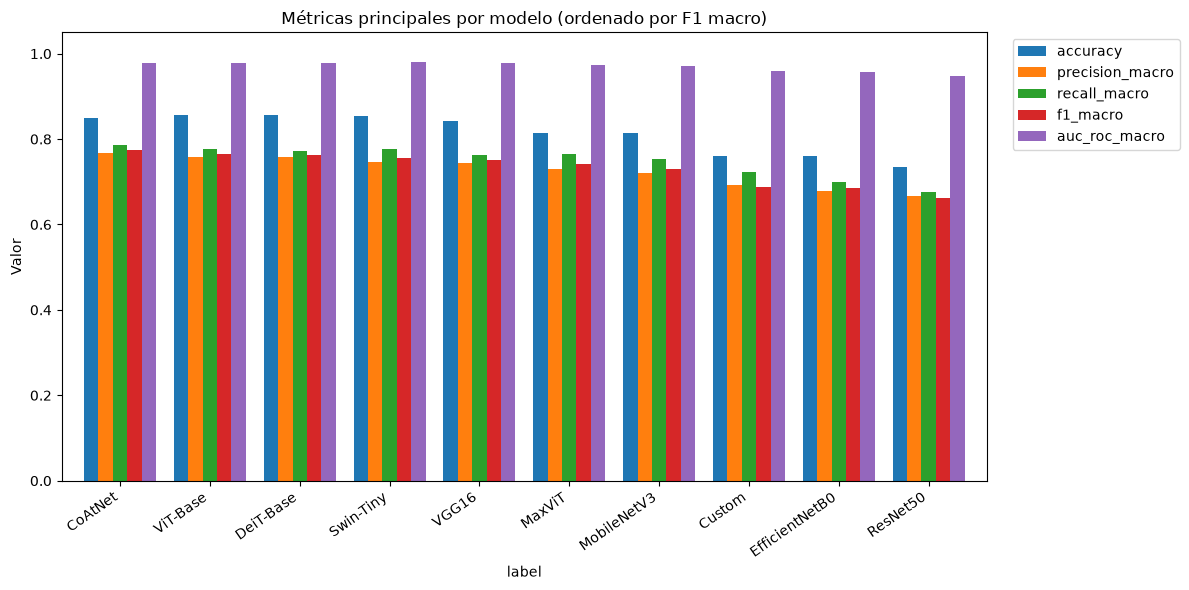

In [4]:
metric_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_roc_macro"]
plot_df = ranking.set_index("label")[metric_cols]

fig, ax = plt.subplots(figsize=(12, 6))
plot_df.plot(kind="bar", ax=ax, width=0.8)
ax.set_ylabel("Valor")
ax.set_ylim(0, 1.05)
ax.set_title("Métricas principales por modelo (ordenado por F1 macro)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metricas_principales.png", dpi=600, bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "metricas_principales.pdf", bbox_inches="tight")
plt.show()

## 4. Precisión vs. costo computacional

Dos vistas del mismo trade-off: F1 macro vs. número de parámetros (escala log, ya que van de 1.5M
a 134M) y F1 macro vs. tiempo de inferencia. El tamaño de cada punto es proporcional al peso del
modelo en disco (MB).

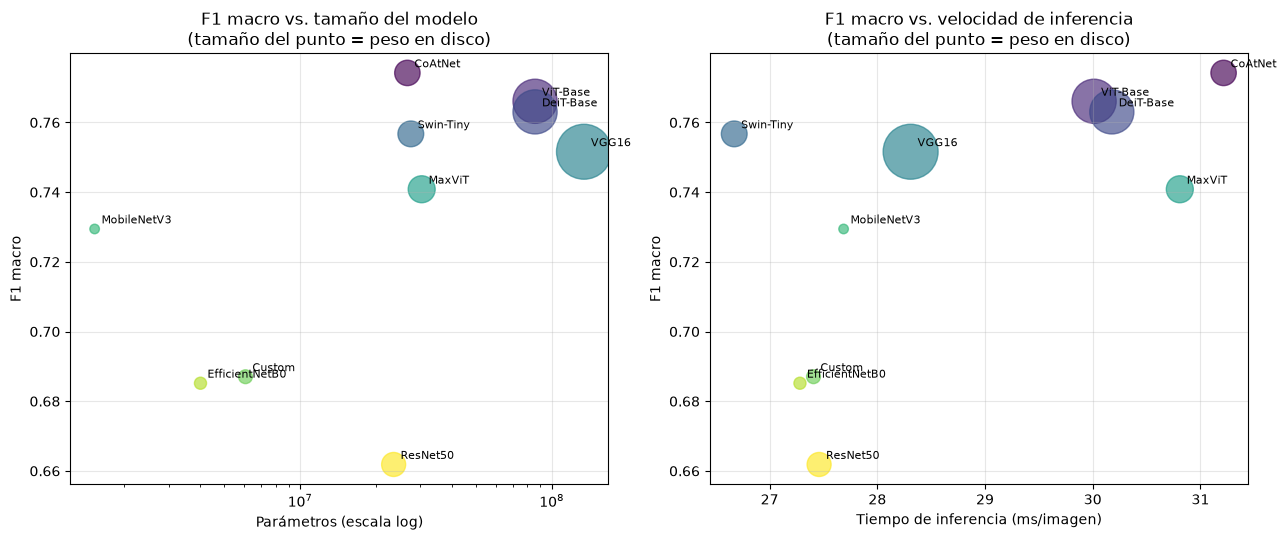

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, (xcol, xlabel, logx) in zip(
    axes,
    [("total_params", "Parámetros (escala log)", True),
     ("inference_time_ms_per_image", "Tiempo de inferencia (ms/imagen)", False)],
):
    sizes = ranking["size_mb"] * 3 + 30
    sc = ax.scatter(ranking[xcol], ranking["f1_macro"], s=sizes, alpha=0.65, c=ranking.index, cmap="viridis")
    for _, row in ranking.iterrows():
        ax.annotate(row["label"], (row[xcol], row["f1_macro"]), fontsize=8,
                    xytext=(5, 4), textcoords="offset points")
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("F1 macro")
    ax.grid(alpha=0.3)

axes[0].set_title("F1 macro vs. tamaño del modelo\n(tamaño del punto = peso en disco)")
axes[1].set_title("F1 macro vs. velocidad de inferencia\n(tamaño del punto = peso en disco)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precision_vs_costo.png", dpi=600, bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "precision_vs_costo.pdf", bbox_inches="tight")
plt.show()

## 5. Cargar predicciones (`.npz`) de los 10 modelos

Necesario para la ROC combinada y las pruebas de significancia (Secciones 7 y 8). Antes de usarlas
para comparar, se verifica que **el test set es idéntico y en el mismo orden** en los 10 — si no lo
fuera, cualquier comparación imagen-a-imagen entre modelos sería inválida.

In [6]:
pred_files = sorted(RESULTS_DIR.glob("*/*_predicciones.npz"))
print(f"Archivos de predicciones encontrados: {len(pred_files)}")

predictions = {}
for f in pred_files:
    data = np.load(f)
    # El nombre de modelo real es el prefijo antes de "__<variante>_predicciones.npz"
    model_name = f.name.split("__")[0]
    label = NICE_NAMES.get(model_name, model_name)
    predictions[label] = {"y_true": data["y_true"], "y_pred": data["y_pred"], "y_prob": data["y_prob"]}

labels = list(predictions.keys())
y_true_ref = predictions[labels[0]]["y_true"]
for label in labels[1:]:
    same = np.array_equal(y_true_ref, predictions[label]["y_true"])
    print(f"  {label}: mismo test set que {labels[0]} -> {same}")
    assert same, f"{label} no comparte el mismo test set/orden -- no se puede comparar imagen a imagen"
print("\nOK: los 10 modelos comparten exactamente el mismo test set, en el mismo orden.")

Archivos de predicciones encontrados: 10
  Custom: mismo test set que CoAtNet -> True
  DeiT-Base: mismo test set que CoAtNet -> True
  EfficientNetB0: mismo test set que CoAtNet -> True
  MaxViT: mismo test set que CoAtNet -> True
  MobileNetV3: mismo test set que CoAtNet -> True
  ResNet50: mismo test set que CoAtNet -> True
  Swin-Tiny: mismo test set que CoAtNet -> True
  VGG16: mismo test set que CoAtNet -> True
  ViT-Base: mismo test set que CoAtNet -> True

OK: los 10 modelos comparten exactamente el mismo test set, en el mismo orden.


## 6. F1 por clase — los 10 modelos a la vez

Reutiliza los `*_metricas_por_clase.csv` que ya guardó cada notebook de entrenamiento.

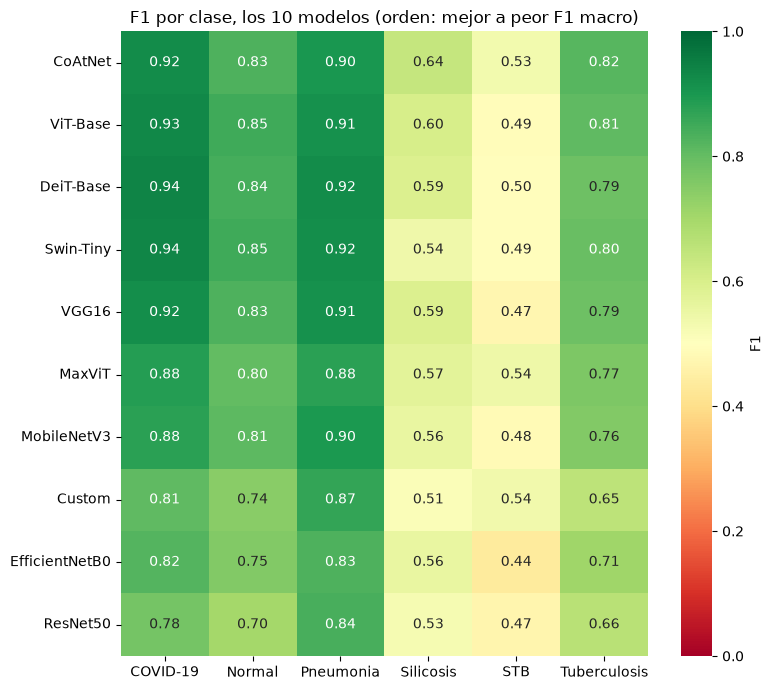

In [7]:
per_class_files = sorted(RESULTS_DIR.glob("*/*_metricas_por_clase.csv"))
per_class_frames = []
for f in per_class_files:
    model_name = f.name.split("__")[0]
    label = NICE_NAMES.get(model_name, model_name)
    df = pd.read_csv(f)
    df["label"] = label
    per_class_frames.append(df)
per_class_all = pd.concat(per_class_frames, ignore_index=True)

f1_pivot = per_class_all.pivot(index="label", columns="class", values="f1").reindex(columns=CLASSES)
f1_pivot = f1_pivot.reindex(ranking["label"])  # mismo orden que el ranking general (mejor a peor)
f1_pivot.to_csv(OUTPUT_DIR / "f1_por_clase_10_modelos.csv")

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(f1_pivot, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1"})
ax.set_title("F1 por clase, los 10 modelos (orden: mejor a peor F1 macro)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "f1_por_clase_heatmap.png", dpi=600, bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "f1_por_clase_heatmap.pdf", bbox_inches="tight")
plt.show()

### 6.1 ¿Silicosis/STB son difíciles solo para algunos modelos, o para todos?

In [8]:
print("Promedio de F1 por clase, a través de los 10 modelos:")
print(f1_pivot.mean().sort_values())
print()
print("Desviación estándar de F1 por clase, a través de los 10 modelos (qué tan parejo es el problema):")
print(f1_pivot.std().sort_values())

Promedio de F1 por clase, a través de los 10 modelos:
class
STB             0.495944
Silicosis       0.568732
Tuberculosis    0.754261
Normal          0.801212
COVID-19        0.881898
Pneumonia       0.887531
dtype: float64

Desviación estándar de F1 por clase, a través de los 10 modelos (qué tan parejo es el problema):
class
Pneumonia       0.033789
STB             0.034589
Silicosis       0.038087
Normal          0.051248
Tuberculosis    0.059311
COVID-19        0.059493
dtype: float64


## 7. Curva ROC macro-promedio combinada

Una curva por modelo (no 6 por modelo x 10 modelos, que sería ilegible): se calcula la ROC
uno-contra-todos de cada una de las 6 clases y se promedian sobre una grilla común de FPR
(macro-average estándar de scikit-learn), quedando una sola curva representativa por modelo.

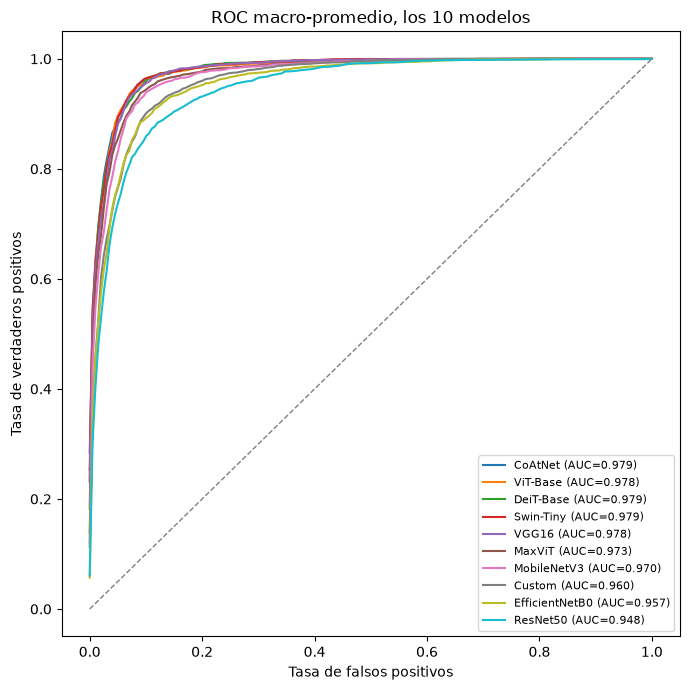

In [9]:
def macro_average_roc(y_true, y_prob, n_classes, n_points=200):
    grid_fpr = np.linspace(0, 1, n_points)
    mean_tpr = np.zeros(n_points)
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve((y_true == i).astype(int), y_prob[:, i])
        mean_tpr += np.interp(grid_fpr, fpr, tpr)
    mean_tpr /= n_classes
    return grid_fpr, mean_tpr

fig, ax = plt.subplots(figsize=(7, 7))
for label in ranking["label"]:  # en orden de ranking, para que la leyenda ya venga ordenada
    p = predictions[label]
    fpr, tpr = macro_average_roc(p["y_true"], p["y_prob"], len(CLASSES))
    auc_macro = ranking.loc[ranking["label"] == label, "auc_roc_macro"].iloc[0]
    ax.plot(fpr, tpr, label=f"{label} (AUC={auc_macro:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("ROC macro-promedio, los 10 modelos")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_combinada_10_modelos.png", dpi=600, bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "roc_combinada_10_modelos.pdf", bbox_inches="tight")
plt.show()

## 8. ¿Las diferencias entre los mejores modelos son reales o son ruido?

Los primeros 4-5 lugares del ranking quedaron muy cerca en F1 macro. Antes de afirmar en el
artículo que "el modelo X es mejor que el modelo Y", conviene comprobar si la diferencia es
estadísticamente significativa. Se usa la **prueba de McNemar** (con corrección de continuidad):
compara, imagen por imagen, en cuáles acierta un modelo y falla el otro (y viceversa) — es la
prueba estándar para comparar dos clasificadores sobre el mismo conjunto de test.

H0: los dos modelos aciertan/fallan por igual (la diferencia observada es ruido de muestreo).
Con p < 0.05 se rechaza H0 -- la diferencia sí es estadísticamente significativa.

In [10]:
def mcnemar_test(y_true, pred_a, pred_b):
    correct_a = pred_a == y_true
    correct_b = pred_b == y_true
    b = int((correct_a & ~correct_b).sum())   # A acierta, B falla
    c = int((~correct_a & correct_b).sum())   # A falla, B acierta
    if b + c == 0:
        return b, c, float("nan"), float("nan")
    stat = (abs(b - c) - 1) ** 2 / (b + c)
    p_value = 1 - chi2.cdf(stat, df=1)
    return b, c, stat, p_value

TOP_N = 5
top_labels = ranking["label"].head(TOP_N).tolist()
print(f"Comparando los {TOP_N} primeros lugares del ranking: {top_labels}\n")

rows = []
for i in range(len(top_labels)):
    for j in range(i + 1, len(top_labels)):
        a, b_label = top_labels[i], top_labels[j]
        b, c, stat, p = mcnemar_test(
            predictions[a]["y_true"], predictions[a]["y_pred"], predictions[b_label]["y_pred"]
        )
        rows.append({
            "modelo_A": a, "modelo_B": b_label,
            "A_acierta_B_falla": b, "A_falla_B_acierta": c,
            "estadistico": stat, "p_valor": p,
            "diferencia_significativa (p<0.05)": p < 0.05 if not np.isnan(p) else None,
        })

mcnemar_df = pd.DataFrame(rows)
mcnemar_df.to_csv(OUTPUT_DIR / "mcnemar_top5.csv", index=False)
mcnemar_df

Comparando los 5 primeros lugares del ranking: ['CoAtNet', 'ViT-Base', 'DeiT-Base', 'Swin-Tiny', 'VGG16']



,modelo_A,modelo_B,A_acierta_B_falla,A_falla_B_acierta,estadistico,p_valor,diferencia_significativa (p<0.05)
0,CoAtNet,ViT-Base,230,252,0.914938,0.338808,False
1,CoAtNet,DeiT-Base,214,236,0.980000,0.322199,False
2,CoAtNet,Swin-Tiny,215,228,0.325056,0.568585,False
3,CoAtNet,VGG16,255,232,0.993840,0.318806,False
4,ViT-Base,DeiT-Base,217,217,0.002304,0.961715,False
5,ViT-Base,Swin-Tiny,201,192,0.162850,0.686546,False
6,ViT-Base,VGG16,259,214,4.093023,0.043061,True
7,DeiT-Base,Swin-Tiny,191,182,0.171582,0.678710,False
8,DeiT-Base,VGG16,255,210,4.163441,0.041305,True
9,Swin-Tiny,VGG16,225,189,2.958937,0.085404,False


## 9. Veredicto

*(Completar/ajustar esta celda con lo que confirme la ejecución real de arriba -- lo que sigue es
la lectura de la corrida ya guardada en `resultados/resultados_entrenamiento/`.)*

- **Ranking por F1 macro**: CoAtNet > ViT-Base > DeiT-Base > Swin-Tiny > VGG16 > MaxViT >
  MobileNetV3 > Custom > EfficientNetB0 > ResNet50. Los primeros 4-5 lugares quedaron dentro de un
  margen de ~0.02 de F1 y ~0.001 de AUC — hay que revisar la Sección 8 antes de declarar un
  "ganador" único: si ninguna de las diferencias entre ellos es significativa (McNemar p>0.05),
  lo correcto para el artículo es reportarlos como estadísticamente empatados, no elegir uno solo.
- **Patrón consistente en los 10 modelos** (Sección 6.1): Silicosis y STB tienen el F1 más bajo en
  absolutamente todos los modelos, pero el AUC-ROC de esas clases se mantiene alto (~0.96-0.98) en
  todos — el problema no es que el modelo no pueda distinguir esas clases en probabilidad, es que
  el umbral de decisión por defecto (argmax) no es el ideal para clases minoritarias incluso con
  `WeightedRandomSampler`. Candidato real para la sección de limitaciones/trabajo futuro del
  artículo (ajuste de umbral por clase).
- **Costo computacional** (Sección 4): MobileNetV3 logra un F1 competitivo con una fracción de los
  parámetros de los modelos más grandes -- argumento directo para la discusión precisión/costo.
- **Modelo custom**: no ganó, pero su comparación justa no es contra el ranking completo sino
  contra modelos de tamaño similar (EfficientNetB0, MobileNetV3) -- ahí sí queda competitivo,
  meritorio considerando que su bloque Transformer se entrena desde cero (sin preentrenar), a
  diferencia de los otros 9 modelos completos.